# Fit a Prony series to a creep curve
Martin Pletz, 2026-10

Tool used: <https://plotdigitizer.com> to copy x and y data from a creep curve like in Fig. 5 of G. Pilz, R.W. Lang, Viscoelastic Properties of Polyethylene for Pipe Applications, in: Proceedings of Plastic Pipes XI, Munich, Germany, 2001

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## Load the data into Python

In [7]:
# t in s, E in MPa

# from plot digitizer
x = [3.7963466404012007, 6.488341846226999, 10.054602862740452, 16.443941242659644, 25.500948790556258, 37.65752133887217, 100.81058827705395, 151.12824636353665, 257.03090316820385, 403.2893515315033, 643.5224897519553, 1014.7907720528015, 1532.8090445397827, 2198.202362435799, 3892.3466635616687, 6384.5369628731805, 10403.375589465119, 15450.539886733646, 25859.113000888607, 40566.28435704769, 62782.38156782762, 91481.63813017597, 152632.56164591492, 236699.65009400403, 383925.83292325155, 606352.4913677151, 895955.7860545298, 1514303.302658434, 2400858.8573788884, 3969806.9668164076, 5966589.633482222, 8849328.272799311, 15051389.93873436, 16880123.852804136, 24054073.430351686, 39537662.931859486, 63816436.63613611, 102796005.52546218, 163869293.20966884, 235394034.00850716, 412316517.2284573, 651829777.8415917, 1018365004.2145853, 1607367849.3019893, 2395526476.393039, 4041127966.1748457, 6538652249.950186, 10395349427.944235]
y = [1930.2149254089966, 1845.7906594550125, 1769.2551743973454, 1693.1431956942001, 1625.434374328703, 1558.3819838990553, 1418.9198109720598, 1357.4383184880066, 1293.1306865064068, 1239.553530147418, 1182.6273009169915, 1136.7313209408446, 1077.9331267729383, 1058.915018475149, 1002.2738912756425, 956.4734048754445, 913.9048354000578, 884.3700571136811, 840.4037692351117, 808.8936875328307, 764.1626653919955, 737.6502920856061, 694.3160407588352, 654.7567448529021, 614.4734960968424, 587.4971155612167, 553.210580199861, 518.5189558684774, 491.7234130723963, 469.98338805657767, 446.4428068244328, 430.46064568135426, 405.80994967930457, 416.3146337661913, 394.7197864751682, 367.0962467374823, 341.38837933537053, 313.5515800503481, 292.50147537848954, 277.82215042522034, 256.8698673305023, 241.103273992227, 226.9703570281506, 213.8301958315213, 202.89095891875613, 195.72462594789602, 186.0863800393614, 179.21638426763263]

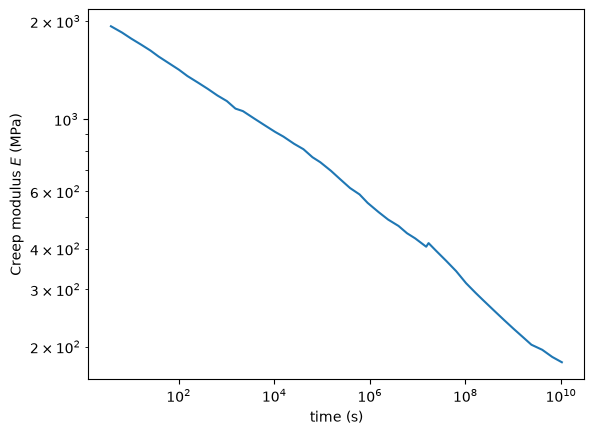

In [8]:
plt.loglog(x,y)
plt.xlabel('time (s)')
plt.ylabel("Creep modulus $E$ (MPa)")
plt.show()

## Fit a Prony series

$E(t) = \sum_{i=1}^{n_{\tau}} (E_i\; e^{−t/\tau_i})\quad\quad\tau_i = \eta_i/E_i$

In [9]:
n_tau = 4

In [10]:
# create tau values in the range of 1 to 1e10
tau_list = np.logspace(0,10,n_tau+2)[1:-1]
tau_list

array([1.e+02, 1.e+04, 1.e+06, 1.e+08])

In [11]:
# function to calulate the creep moduls E(t)
def e_mod(t, e_inf, *e):
    e_for_t = e_inf
    for e_i, tau_i in zip(e, tau_list):
        e_for_t += e_i * np.exp(-t / tau_i)
    return e_for_t

In [12]:
p0 = np.ones(n_tau + 1) 

# fit the e_i values to the test data
e_fit_par = curve_fit(e_mod,x,y,p0)[0]
e_fit_par

array([219.74346885, 657.08820548, 423.77055014, 313.63372781,
       229.54935837])

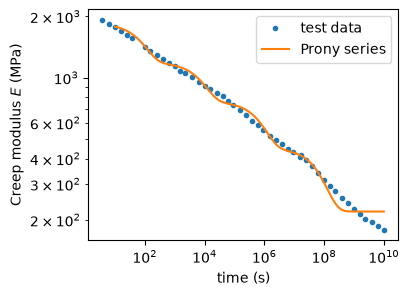

In [13]:
# check how good the fit works for test data
plt.figure(figsize=(4,3))

t_arr = np.logspace(1,10,400)
e_fit_arr = e_mod(t_arr,*e_fit_par)

plt.loglog(x,y,'.',label='test data')
plt.loglog(t_arr,e_fit_arr,label='Prony series')
plt.xlabel('time (s)')
plt.ylabel("Creep modulus $E$ (MPa)")
plt.legend()
plt.show()

## Prepare Prony series for the Abaqus model

**Definition in Abaqus** ($G$ and $K$ separately):

$G(t) = G_0 \left( 1 − \sum_i g_i (1 − e^{−t/\tau_i}) \right)$

with

$g_i = G_i/G_0 \quad\quad \mathrm{and} \quad\quad G_0 = \sum_i G_i$

--> create `elastic` material property with $E_0$ (*instantaneous*) and $\nu$ plus `viscoelastic` properties with the *Time domain* selected and a list of $(g_i, k_i, \tau_i)$

In [14]:
# initial Young's modulus, nu = 0.3
E0 = sum(e_fit_par)
print(E0)

1843.7853106567218


In [15]:
# as input in Abaqus: relative E values: g
g_list = e_fit_par[1:]/E0

# abaqus list: g_i, k_i, tau_i
out_list = np.column_stack((g_list, np.zeros(n_tau),tau_list))
#np.savetxt('prony-series.txt',out_list,delimiter=', ',fmt="%.5e")
#np.savetxt('prony-series-gk.txt',np.column_stack((g_list,g_list,tau_list)),delimiter=', ',fmt="%.5e")

In [16]:
# print in a way to copy into Abaqus CAE
s = np.array2string(out_list, separator="\t")
print(s.replace("[", "").replace("]", ""))

3.56379998e-01	0.00000000e+00	1.00000000e+02
 2.29837253e-01	0.00000000e+00	1.00000000e+04
 1.70103171e-01	0.00000000e+00	1.00000000e+06
 1.24498963e-01	0.00000000e+00	1.00000000e+08


In [17]:
# time of 40 years in seconds
40*365*24*3600

1261440000